# EN4554 Assignment 2 — Task 3: Regularization and Residual Connections

**Name:** _your name_  **Index number:** _your index_

**GitHub:** https://github.com/chamudiR/EN4554-Assignment-2-on-CNNs

<a href="https://colab.research.google.com/github/chamudiR/EN4554-Assignment-2-on-CNNs/blob/main/Task3_Regularization_ResNets.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Use of AI tools:** Claude (Anthropic) was used to help write the code in this notebook. I have gone through and understood all of it.

**Runtime:** Colab T4 GPU (*Runtime → Change runtime type → T4 GPU*). Measured times:
* **3(a):** 7 methods × 3 seeds × 100 epochs on 5k images, about 15 min (about 43 s per run).
* **3(b):** 6 networks × 30 epochs on 45k images, about 25 min (plain-8 ≈ 75 s, plain-20 ≈ 165 s, plain-56 ≈ 7.5 min, and similar for the residual networks).

Downloading CIFAR-10 can take longer than the training itself when the download server is slow (up to 47 min in my runs).

If time is short, reduce `SEEDS_3A` or `EPOCHS_3B`. The training loops skip runs that have already finished, so if a cell is interrupted, re-running it continues where it stopped (as long as the Colab runtime was not reset).

## 0. Setup

This uses the same data pipeline as Tasks 1 and 2:
* Fixed seeds.
* **45 000 train / 5 000 validation** split.
* Per-channel normalisation with statistics from the **training split only**.
* The **test set is not loaded**.

All data stays on the GPU, and augmentations are implemented as batched tensor operations on the GPU. Training uses mixed precision (`torch.autocast` with float16 and a `GradScaler`), which uses the T4's tensor cores and speeds up training roughly 2×.

In [ ]:
import math, random, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt

SEED = 42

def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()
torch.backends.cudnn.benchmark = True       # fastest conv algorithms; runs are seeded but not bit-reproducible

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
use_amp = device.type == 'cuda'
print('PyTorch', torch.__version__, '| device:', device,
      '|', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'CPU')

PyTorch 2.11.0+cu130 | device: cuda | Tesla T4


In [ ]:
# ---- Load CIFAR-10 training set and make the 45k / 5k split (identical to Tasks 1 and 2) ----
train_full = torchvision.datasets.CIFAR10(root='./data', train=True, download=True)
CLASSES = train_full.classes

X_all = torch.from_numpy(train_full.data).float().div(255).permute(0, 3, 1, 2)  # (50000, 3, 32, 32) in [0, 1]
y_all = torch.tensor(train_full.targets, dtype=torch.long)

perm = torch.randperm(len(X_all), generator=torch.Generator().manual_seed(SEED))
train_idx, val_idx = perm[:45000], perm[45000:]
X_train, y_train = X_all[train_idx], y_all[train_idx]
X_val,   y_val   = X_all[val_idx],   y_all[val_idx]

# ---- Per-channel normalisation with TRAINING statistics only ----
mean = X_train.mean(dim=(0, 2, 3))
std  = X_train.std(dim=(0, 2, 3))
X_train = (X_train - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)
X_val   = (X_val   - mean.view(1, 3, 1, 1)) / std.view(1, 3, 1, 1)

Xtr, ytr = X_train.to(device), y_train.to(device)
Xva, yva = X_val.to(device),   y_val.to(device)

# ---- 5k training subset for 3(a): 500 images per class, drawn from the 45k training split ----
g = torch.Generator().manual_seed(SEED)
idx5k = torch.cat([torch.nonzero(y_train == c).squeeze(1)[torch.randperm(int((y_train == c).sum()), generator=g)[:500]]
                   for c in range(10)])
X5k, y5k = Xtr[idx5k.to(device)], ytr[idx5k.to(device)]

print('train', tuple(Xtr.shape), '| val', tuple(Xva.shape), '| 5k subset', tuple(X5k.shape))
print('5k subset class counts:', torch.bincount(y5k, minlength=10).tolist())

100%|██████████| 170M/170M [46:58<00:00, 60.5kB/s]


train (45000, 3, 32, 32) | val (5000, 3, 32, 32) | 5k subset (5000, 3, 32, 32)
5k subset class counts: [500, 500, 500, 500, 500, 500, 500, 500, 500, 500]


## Shared training utilities

**Augmentations.** Each one works on a whole mini-batch on the GPU and draws different random parameters for every image.

* **Flip + crop** (standard CIFAR augmentation). Each image is flipped horizontally with probability ½. It is then zero-padded by 4 pixels on each side and a random 32×32 crop is taken. After normalisation, zero is the mean pixel.
* **Cutout** (DeVries & Taylor, 2017; my implementation). A 16×16 square is set to zero in every image. Its centre is uniform over the image, so the square may be partly outside the image, as in the paper. The network can no longer rely on any single local region, such as a dog's face, and has to use the whole object.
* **Mixup** (Zhang et al., 2018; my implementation). Draw $\lambda \sim \mathrm{Beta}(\alpha, \alpha)$ once per batch, with $\alpha = 1$ for CIFAR-10 as in the paper. Pair each image with a random other image in the batch, train on $\tilde x = \lambda x_i + (1-\lambda) x_j$, and use the loss $\lambda\,\mathrm{CE}(f(\tilde x), y_i) + (1-\lambda)\,\mathrm{CE}(f(\tilde x), y_j)$. This is equivalent to training on soft labels $\lambda y_i + (1-\lambda) y_j$. It encourages the network to behave linearly between training examples and discourages over-confident, memorised decision boundaries.

**Training loop.** The optimizer is SGD with momentum 0.9. The learning-rate schedule is cosine annealing to 0, with an optional linear warm-up, and it is updated every step. Mixed precision is used.

Training *accuracy* is measured on the **clean (un-augmented) training images in eval mode** at the end of every epoch. The running accuracy on augmented or mixed batches would not be comparable between methods, and with mixup it is not even well defined.

In [ ]:
def random_flip_crop(x, pad=4):
    n, c, h, w = x.shape
    dev = x.device
    flip = torch.rand(n, device=dev) < 0.5
    x = torch.where(flip.view(n, 1, 1, 1), x.flip(3), x)
    xp = F.pad(x, (pad, pad, pad, pad))                       # zero = mean pixel after normalisation
    i = torch.randint(0, 2 * pad + 1, (n,), device=dev)        # top-left corner of each crop
    j = torch.randint(0, 2 * pad + 1, (n,), device=dev)
    rows = (i.view(n, 1) + torch.arange(h, device=dev)).view(n, 1, h, 1)
    cols = (j.view(n, 1) + torch.arange(w, device=dev)).view(n, 1, 1, w)
    return xp[torch.arange(n, device=dev).view(n, 1, 1, 1), torch.arange(c, device=dev).view(1, c, 1, 1), rows, cols]


def cutout(x, size=16):
    n, _, h, w = x.shape
    dev = x.device
    cy = torch.randint(0, h, (n, 1, 1), device=dev)            # centre of the square, anywhere in the image
    cx = torch.randint(0, w, (n, 1, 1), device=dev)
    ys = torch.arange(h, device=dev).view(1, h, 1)
    xs = torch.arange(w, device=dev).view(1, 1, w)
    hole = (ys >= cy - size // 2) & (ys < cy + size // 2) & (xs >= cx - size // 2) & (xs < cx + size // 2)
    return x * (~hole).unsqueeze(1).to(x.dtype)                # (n, 1, h, w) mask broadcast over channels


def mixup(x, y, alpha=1.0):
    lam = float(np.random.beta(alpha, alpha))
    perm = torch.randperm(len(x), device=x.device)
    return lam * x + (1 - lam) * x[perm], y, y[perm], lam

In [ ]:
# Visual check of the augmentations on a few training images
def to_img(x):
    return (x.cpu() * std.view(3, 1, 1) + mean.view(3, 1, 1)).clamp(0, 1).permute(1, 2, 0).numpy()

set_seed(0)
show = torch.randperm(len(X5k), generator=torch.Generator().manual_seed(0))[:6].to(device)  # X5k is sorted by class
xs, ys = X5k[show], y5k[show]
mixed, ya, yb, lam = mixup(xs, ys)
rows = [('original', xs), ('flip + crop', random_flip_crop(xs)), ('cutout', cutout(xs)), (f'mixup (λ={lam:.2f})', mixed)]
fig, ax = plt.subplots(4, 6, figsize=(10, 7))
for r, (name, batch) in enumerate(rows):
    for c in range(6):
        ax[r, c].imshow(to_img(batch[c])); ax[r, c].set_xticks([]); ax[r, c].set_yticks([])
        if r == 3:
            ax[r, c].set_xlabel(f'{CLASSES[ya[c]]} / {CLASSES[yb[c]]}', fontsize=7)
        elif r == 0:
            ax[r, c].set_title(CLASSES[ys[c]], fontsize=8)
    ax[r, 0].set_ylabel(name)
plt.suptitle('Augmentations used in 3(a)'); plt.tight_layout(); plt.show()

In [ ]:
@torch.no_grad()
def evaluate(model, X, y, batch=1000):
    model.eval()
    loss_sum, correct = 0.0, 0
    for i in range(0, len(X), batch):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
            out = model(X[i:i + batch])
        loss_sum += F.cross_entropy(out.float(), y[i:i + batch], reduction='sum').item()
        correct += (out.argmax(1) == y[i:i + batch]).sum().item()
    return loss_sum / len(X), correct / len(X)


def train_run(model, X, y, epochs, lr, weight_decay=0.0, batch_size=128, augment=(), mixup_alpha=0.0,
              warmup_epochs=0, eval_train=False, seed=SEED, log_every=0):
    opt = torch.optim.SGD(model.parameters(), lr=lr, momentum=0.9, weight_decay=weight_decay)
    steps_per_epoch = math.ceil(len(X) / batch_size)
    total, warm = epochs * steps_per_epoch, warmup_epochs * steps_per_epoch

    def lr_factor(step):                                       # linear warm-up, then cosine decay to 0
        if step < warm:
            return (step + 1) / warm
        return 0.5 * (1 + math.cos(math.pi * (step - warm) / max(1, total - warm)))

    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_factor)
    scaler = torch.amp.GradScaler('cuda', enabled=use_amp)
    gen = torch.Generator().manual_seed(seed)                  # mini-batch order
    hist = {k: [] for k in ['train_loss', 'train_acc', 'val_loss', 'val_acc']}
    t0 = time.time()
    for ep in range(1, epochs + 1):
        model.train()
        order = torch.randperm(len(X), generator=gen).to(X.device)
        loss_sum = torch.zeros((), device=X.device)
        for i in range(0, len(X), batch_size):
            idx = order[i:i + batch_size]
            xb, yb = X[idx], y[idx]
            for aug in augment:
                xb = aug(xb)
            if mixup_alpha > 0:
                xb, ya, yb2, lam = mixup(xb, yb, mixup_alpha)
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out = model(xb)
                if mixup_alpha > 0:
                    loss = lam * F.cross_entropy(out, ya) + (1 - lam) * F.cross_entropy(out, yb2)
                else:
                    loss = F.cross_entropy(out, yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.step(opt)
            scaler.update()
            sched.step()
            loss_sum += loss.detach().float() * len(idx)
        hist['train_loss'].append(loss_sum.item() / len(X))   # on the (augmented) training batches
        if eval_train:
            hist['train_acc'].append(evaluate(model, X, y)[1])  # clean images, eval mode
        vl, va = evaluate(model, Xva, yva)
        hist['val_loss'].append(vl); hist['val_acc'].append(va)
        if log_every and (ep % log_every == 0 or ep == epochs):
            tr = f' train acc {hist["train_acc"][-1]:.4f} |' if eval_train else ''
            print(f'    epoch {ep:3d} | train loss {hist["train_loss"][-1]:.4f} |{tr} val acc {va:.4f} | {time.time() - t0:.0f}s')
    hist['time'] = time.time() - t0
    return hist

## Task 3(a): Regularization on a 5k-image training set

**Model.** The model is a small CNN with batch norm:
* Two conv blocks at 32 channels, then max-pool.
* Two conv blocks at 64 channels, then max-pool.
* One conv block at 128 channels, then max-pool.
* FC 2048 → 256 → 10.

Each conv block is Conv3×3 → BN → ReLU. The model has about 670k parameters, far more than 5k images can constrain, so the baseline is expected to overfit heavily.

**Setup.**
* **Data:** 5 000 training images (500 per class); the full 5k validation split is used.
* **Training:** SGD with momentum 0.9, lr 0.05 with cosine decay, batch size 128, **100 epochs**.
* **Seeds:** each method is run with **3 seeds** (initialisation and batch order). The table reports mean ± standard deviation.

| Method | What changes |
|---|---|
| baseline | nothing |
| weight decay | L2 penalty $5\times10^{-4}$ (through SGD's `weight_decay`) |
| dropout | `Dropout(0.5)` before both fully connected layers |
| flip+crop | random horizontal flip + 4-pixel-padded random crop |
| cutout | one 16×16 square zeroed per image |
| mixup | $\alpha = 1$ |
| all combined | weight decay + dropout + flip+crop + cutout + mixup |

Dropout is placed only in the classifier, after the last BN layer. Dropout before a BN layer changes the activation variance between training and evaluation ("variance shift"), which hurts BN networks.

In [ ]:
class SmallBNCNN(nn.Module):
    def __init__(self, dropout=0.0):
        super().__init__()
        def block(cin, cout):
            return [nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True)]
        self.features = nn.Sequential(
            *block(3, 32),  *block(32, 32), nn.MaxPool2d(2),     # 32 -> 16
            *block(32, 64), *block(64, 64), nn.MaxPool2d(2),     # 16 -> 8
            *block(64, 128),                nn.MaxPool2d(2))     # 8 -> 4
        self.classifier = nn.Sequential(
            nn.Flatten(), nn.Dropout(dropout), nn.Linear(128 * 4 * 4, 256), nn.ReLU(inplace=True),
            nn.Dropout(dropout), nn.Linear(256, 10))

    def forward(self, x):
        return self.classifier(self.features(x))


print('SmallBNCNN parameters:', sum(p.numel() for p in SmallBNCNN().parameters()))

CONFIGS_3A = {
    'baseline':     dict(),
    'weight decay': dict(weight_decay=5e-4),
    'dropout':      dict(dropout=0.5),
    'flip+crop':    dict(augment=(random_flip_crop,)),
    'cutout':       dict(augment=(cutout,)),
    'mixup':        dict(mixup_alpha=1.0),
    'all combined': dict(weight_decay=5e-4, dropout=0.5, augment=(random_flip_crop, cutout), mixup_alpha=1.0),
}
EPOCHS_3A = 100
SEEDS_3A = [0, 1, 2]
results3a = {}

SmallBNCNN parameters: 666858


In [ ]:
for name, cfg in CONFIGS_3A.items():
    for seed in SEEDS_3A:
        if (name, seed) in results3a:                      # already done (allows resuming)
            continue
        set_seed(seed)
        model = SmallBNCNN(dropout=cfg.get('dropout', 0.0)).to(device)
        h = train_run(model, X5k, y5k, EPOCHS_3A, lr=0.05,
                      weight_decay=cfg.get('weight_decay', 0.0), augment=cfg.get('augment', ()),
                      mixup_alpha=cfg.get('mixup_alpha', 0.0), eval_train=True, seed=seed)
        results3a[(name, seed)] = h
        print(f'{name:>13} seed {seed} | train acc {h["train_acc"][-1] * 100:6.2f}% | '
              f'val acc {h["val_acc"][-1] * 100:6.2f}% (best {max(h["val_acc"]) * 100:6.2f}%) | {h["time"]:.0f}s')

     baseline seed 0 | train acc 100.00% | val acc  66.42% (best  66.72%) | 45s
     baseline seed 1 | train acc 100.00% | val acc  66.34% (best  66.72%) | 39s
     baseline seed 2 | train acc 100.00% | val acc  67.72% (best  68.48%) | 41s
 weight decay seed 0 | train acc 100.00% | val acc  66.80% (best  67.26%) | 43s
 weight decay seed 1 | train acc 100.00% | val acc  68.68% (best  68.84%) | 42s
 weight decay seed 2 | train acc 100.00% | val acc  68.88% (best  68.90%) | 43s
      dropout seed 0 | train acc  99.86% | val acc  71.06% (best  71.36%) | 42s
      dropout seed 1 | train acc  99.96% | val acc  70.12% (best  70.62%) | 43s
      dropout seed 2 | train acc  99.98% | val acc  70.52% (best  70.52%) | 43s
    flip+crop seed 0 | train acc  98.98% | val acc  75.64% (best  75.76%) | 43s
    flip+crop seed 1 | train acc  99.34% | val acc  75.20% (best  75.62%) | 43s
    flip+crop seed 2 | train acc  99.24% | val acc  75.90% (best  76.34%) | 43s
       cutout seed 0 | train acc 100.00%

In [ ]:
def stat(name, key, fn=lambda v: v[-1]):
    return np.array([fn(results3a[(name, s)][key]) for s in SEEDS_3A]) * 100

rows = []
for name in CONFIGS_3A:
    tr, va = stat(name, 'train_acc'), stat(name, 'val_acc')
    gap, best = tr - va, stat(name, 'val_acc', max)
    rows.append({'method': name,
                 'train acc (%)': f'{tr.mean():.2f} ± {tr.std():.2f}',
                 'val acc (%)':   f'{va.mean():.2f} ± {va.std():.2f}',
                 'gap (train − val)': f'{gap.mean():.2f} ± {gap.std():.2f}',
                 'best val acc (%)': f'{best.mean():.2f} ± {best.std():.2f}'})
table3a = pd.DataFrame(rows)
print(f'Final-epoch accuracies after {EPOCHS_3A} epochs, mean ± std over seeds {SEEDS_3A}. '
      'Train accuracy is measured on clean training images.')
display(table3a)

Final-epoch accuracies after 100 epochs, mean ± std over seeds [0, 1, 2]. Train accuracy is measured on clean training images.


,method,train acc (%),val acc (%),gap (train − val),best val acc (%)
0,baseline,100.00 ± 0.00,66.83 ± 0.63,33.17 ± 0.63,67.31 ± 0.83
1,weight decay,100.00 ± 0.00,68.12 ± 0.94,31.88 ± 0.94,68.33 ± 0.76
2,dropout,99.93 ± 0.05,70.57 ± 0.39,29.37 ± 0.43,70.83 ± 0.37
3,flip+crop,99.19 ± 0.15,75.58 ± 0.29,23.61 ± 0.38,75.91 ± 0.31
4,cutout,99.99 ± 0.02,69.65 ± 1.04,30.34 ± 1.05,70.01 ± 0.98
5,mixup,99.98 ± 0.02,66.91 ± 1.03,33.07 ± 1.02,67.86 ± 0.36
6,all combined,73.61 ± 0.69,67.93 ± 1.11,5.69 ± 0.49,68.71 ± 0.66


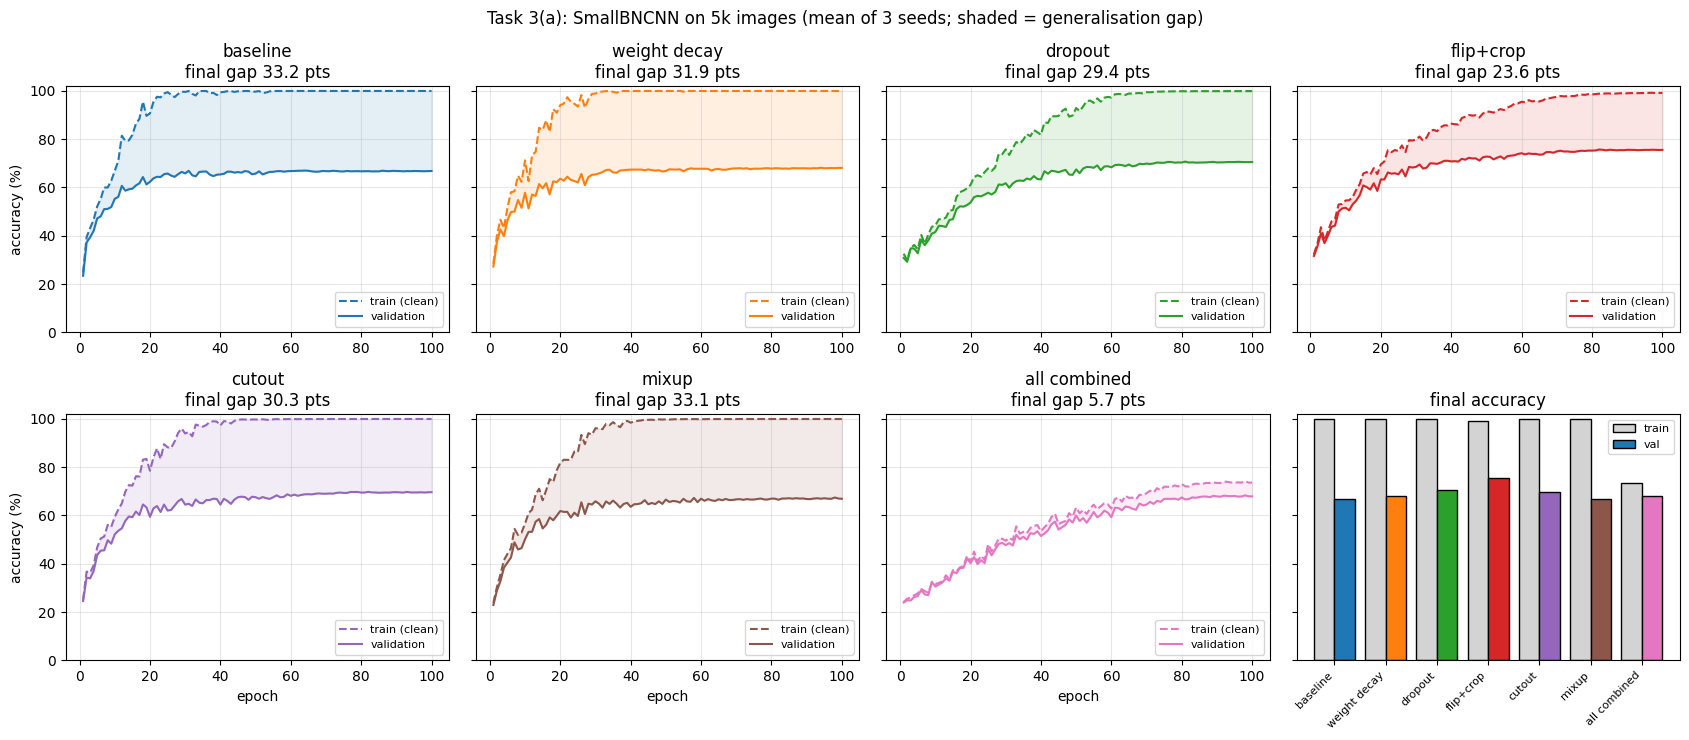

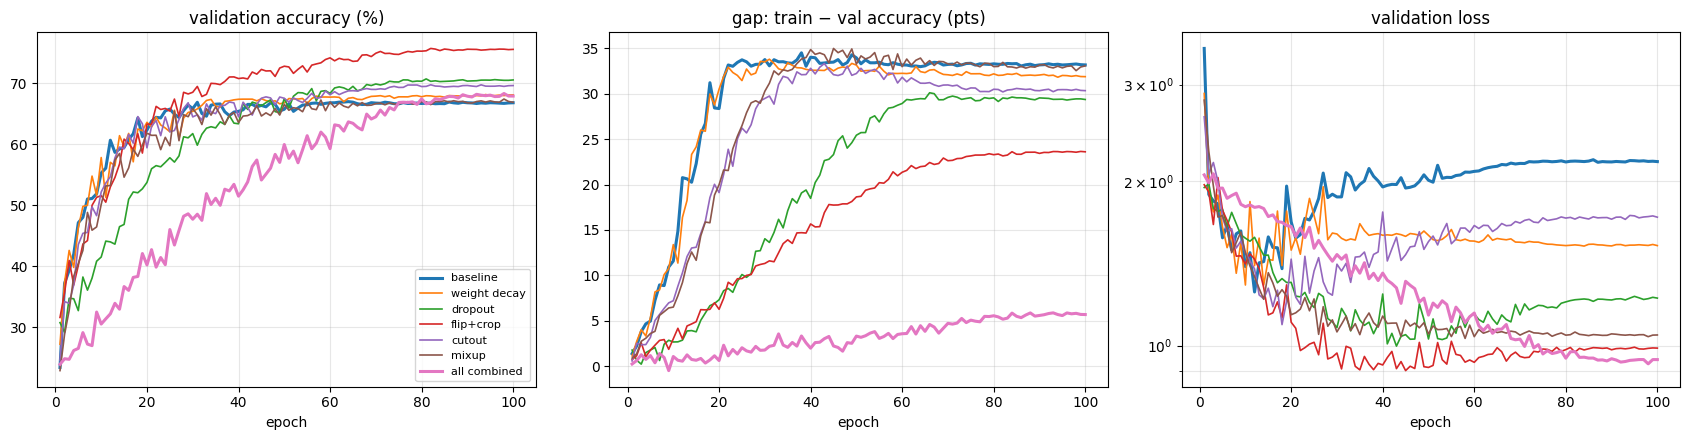

In [ ]:
def curve(name, key):
    return np.mean([results3a[(name, s)][key] for s in SEEDS_3A], axis=0) * 100

ep = np.arange(1, EPOCHS_3A + 1)
colors = {n: f'C{i}' for i, n in enumerate(CONFIGS_3A)}

# Small multiples: train vs val accuracy for each method
fig, axes = plt.subplots(2, 4, figsize=(17, 7.5), sharey=True)
for ax, name in zip(axes.flat, CONFIGS_3A):
    tr, va = curve(name, 'train_acc'), curve(name, 'val_acc')
    ax.plot(ep, tr, color=colors[name], ls='--', label='train (clean)')
    ax.plot(ep, va, color=colors[name], label='validation')
    ax.fill_between(ep, va, tr, color=colors[name], alpha=0.12)
    ax.set_title(f'{name}\nfinal gap {tr[-1] - va[-1]:.1f} pts')
    ax.set_ylim(0, 102); ax.grid(alpha=0.3); ax.legend(loc='lower right', fontsize=8)
for ax in axes[1, :3]:
    ax.set_xlabel('epoch')
for ax in axes[:, 0]:
    ax.set_ylabel('accuracy (%)')

ax = axes[1, 3]                                            # 8th panel: summary bar chart
x = np.arange(len(CONFIGS_3A))
tr_f = [stat(n, 'train_acc').mean() for n in CONFIGS_3A]
va_f = [stat(n, 'val_acc').mean() for n in CONFIGS_3A]
ax.bar(x - 0.2, tr_f, 0.4, color='lightgrey', edgecolor='k', label='train')
ax.bar(x + 0.2, va_f, 0.4, color=[colors[n] for n in CONFIGS_3A], edgecolor='k', label='val')
ax.set_xticks(x); ax.set_xticklabels(CONFIGS_3A, rotation=45, ha='right', fontsize=8)
ax.set_title('final accuracy'); ax.legend(fontsize=8)
fig.suptitle(f'Task 3(a): SmallBNCNN on 5k images (mean of {len(SEEDS_3A)} seeds; shaded = generalisation gap)')
plt.tight_layout(); plt.show()

# Overlays: validation accuracy, generalisation gap and validation loss
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name in CONFIGS_3A:
    lw = 2.2 if name in ('baseline', 'all combined') else 1.2
    ax[0].plot(ep, curve(name, 'val_acc'), color=colors[name], lw=lw, label=name)
    ax[1].plot(ep, curve(name, 'train_acc') - curve(name, 'val_acc'), color=colors[name], lw=lw, label=name)
    ax[2].plot(ep, curve(name, 'val_loss') / 100, color=colors[name], lw=lw, label=name)
ax[0].set_title('validation accuracy (%)'); ax[1].set_title('gap: train − val accuracy (pts)')
ax[2].set_title('validation loss'); ax[2].set_yscale('log')
for a in ax:
    a.set_xlabel('epoch'); a.grid(alpha=0.3, which='both')
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**

Final-epoch results after 100 epochs (mean ± std over 3 seeds). Training accuracy is on clean images.

| method | train acc (%) | val acc (%) | gap (pts) | val acc vs baseline |
|---|---|---|---|---|
| baseline | 100.00 | 66.83 ± 0.63 | 33.2 | — |
| weight decay | 100.00 | 68.12 ± 0.94 | 31.9 | +1.3 |
| dropout | 99.93 | 70.57 ± 0.39 | 29.4 | +3.7 |
| **flip+crop** | 99.19 | **75.58 ± 0.29** | 23.6 | **+8.8** |
| cutout | 99.99 | 69.65 ± 1.04 | 30.3 | +2.8 |
| mixup | 99.98 | 66.91 ± 1.03 | 33.1 | +0.1 |
| all combined | 73.61 | 67.93 ± 1.11 | **5.7** | +1.1 |

* **Baseline: complete memorisation.** The network has about 667k parameters, roughly 133 per training image. Clean training accuracy reaches 100% by about epoch 30, while validation accuracy levels off at about 67%, a gap of 33 points. The validation loss falls to about 1.3 around epoch 15 and then climbs to about 2.2. After that point the network becomes increasingly over-confident on validation images it gets wrong, while its accuracy no longer changes.
* **How reliable the differences are.** With 3 seeds the standard deviations are 0.3–1.1 points. Gains of about 1 point (weight decay, mixup, all combined) are therefore at the level of seed-to-seed noise. Flip + crop (+8.8, std 0.29) and dropout (+3.7, std 0.39) are clearly real improvements.
* **Flip + crop: by far the best (+8.8 points, 75.6%).**
  * **Why it works:** a mirrored or slightly shifted cat is still a cat, so this augmentation encodes *true invariances* of the CIFAR-10 classes. Each image yields up to 2 flips × 81 crop positions = 162 plausible variants, which effectively enlarges the 5k training set.
  * **It does not stop memorisation:** the model still reaches 99% clean training accuracy. What changes is that it learns features that transfer, so validation accuracy rises instead of training accuracy falling.
  * **Other signs:** it has the smallest gap of any single method (23.6), the lowest seed variance and one of the lowest validation losses (about 1.0).
* **Dropout: second best (+3.7 points).** Dropout acts only on the classifier, but that is where 79% of the parameters are: the 2048→256 FC layer alone has 524k of the 667k. It slows memorisation, as the gap curve shows: clean training accuracy approaches 100% only around epochs 60–70, against epoch 30 for the baseline. That leaves more of training in the regime where the features still generalise.
* **Weight decay: a small effect (+1.3, within noise).** Training accuracy still reaches 100%. Its main visible effect is a lower validation loss (about 1.55, against 2.2), because smaller weights mean less extreme logits. The conv layers are followed by batch norm, which makes the network's output independent of the scale of their weights. Weight decay therefore does not reduce their capacity; it mostly raises their effective learning rate. Only the FC layers are truly constrained.
* **Cutout: a moderate, noisy gain (+2.8 ± 1.0).** Training accuracy still reaches 100%. On a 32×32 image the 16×16 square removes up to a quarter of the image, often much of the object itself. That is a strong perturbation for a small network trained for only 100 epochs. In the original paper cutout was used with large ResNets and much longer schedules.
* **Mixup: no accuracy gain (66.9% vs 66.8%), but much better calibrated.**
  * **Validation loss:** mixup ends at about 1.05, against the baseline's 2.2, the largest improvement in validation loss among the single methods.
  * **Why loss improves but accuracy does not:** training on soft, mixed targets penalises over-confident predictions. The network therefore makes far fewer *confident* mistakes, but which class it ranks highest on validation images is largely unchanged.
  * **Memorisation continues:** clean training accuracy is still 99.98%, so the network still memorises the 5k original images. With a small model and limited data, mixup alone does not improve generalisation here. Its reported gains come from larger networks and longer training.
* **All combined: the smallest gap (5.7) but *underfitting*.**
  * **Training accuracy drops to 73.6%:** five regularisers at once are too strong for a 667k-parameter network trained for 100 epochs.
  * **The gap closes from the wrong side:** it shrinks mainly because *training* accuracy falls, not because validation accuracy rises. Validation accuracy (67.9%) is 7.7 points *below* flip + crop alone.
  * **Still improving at the end:** its validation accuracy was still slowly climbing at epoch 100, when the cosine schedule had already reduced the learning rate to zero. A longer schedule or a larger model would let it use the extra regularisation.
  * **Best calibrated:** it does have the lowest validation loss (about 0.95).
* **Overall.**
  * **The most effective regulariser** is the one that encodes real invariances of the data (flip + crop), not the one that changes the training signal the most.
  * **Three different measures:** the gap, the validation loss and the validation accuracy measure different things. A small gap can mean underfitting (all combined), and a much better validation loss can come with no accuracy gain (mixup).
  * **Combining regularisers** must be done selectively, with their strengths tuned to the model size and training length. For example, flip + crop with dropout is a natural candidate for Task 4.

## Task 3(b): Plain vs residual networks of depth $6n+2$ (8, 20, 56)

**Architecture.** CIFAR-style networks as in He et al. (2016), §4.2:
* Conv3×3(16) → BN → ReLU.
* Three stages of $n$ blocks with 16, 32 and 64 channels. Feature maps are 32×32, 16×16 and 8×8. The first block of stages 2 and 3 halves the resolution with stride 2.
* Global average pooling, then FC 64 → 10.

Each block is Conv3×3 → BN → ReLU → Conv3×3 → BN, followed by a final ReLU, and contributes 2 weight layers. The depth is therefore $1 + 6n + 1 = 6n + 2$, giving $n = 1, 3, 9$ for depths 8, 20 and 56.

**The only difference is the shortcut.**
* Residual block: $\mathrm{ReLU}(F(x) + \text{shortcut}(x))$.
* Plain block: $\mathrm{ReLU}(F(x))$.

The shortcut is the identity. Where the shape changes, it uses the paper's *option A*: subsample with stride 2 and zero-pad the extra channels. Option A has **no parameters**, so each plain network and its residual counterpart have *exactly* the same parameter count and initial weights.

**Initialisation.** Conv and FC weights use Kaiming normal (fan-out, ReLU). BN starts with $\gamma = 1, \beta = 0$.

**Training.**
* **Data:** all 45k training images, with flip + crop augmentation as in the paper.
* **Optimizer:** SGD with momentum 0.9, lr 0.1, weight decay $10^{-4}$, batch size 128.
* **Schedule:** 1 epoch of linear warm-up, then cosine decay over **30 epochs**.
* All six networks use the same seed and the same settings.

In [ ]:
class BasicBlock(nn.Module):
    def __init__(self, cin, cout, stride, residual):
        super().__init__()
        self.conv1 = nn.Conv2d(cin, cout, 3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(cout)
        self.conv2 = nn.Conv2d(cout, cout, 3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(cout)
        self.residual = residual
        self.extra_ch = cout - cin
        self.stride = stride

    def shortcut(self, x):
        # Option A: identity; when the shape changes, subsample and zero-pad channels (no parameters)
        if self.stride != 1:
            x = x[:, :, ::self.stride, ::self.stride]
        if self.extra_ch > 0:
            x = F.pad(x, (0, 0, 0, 0, self.extra_ch // 2, self.extra_ch - self.extra_ch // 2))
        return x

    def forward(self, x):
        out = F.relu(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        if self.residual:
            out = out + self.shortcut(x)          # the ONLY difference between plain and residual
        return F.relu(out)


class CifarNet(nn.Module):
    def __init__(self, depth, residual):
        super().__init__()
        assert (depth - 2) % 6 == 0, 'depth must be 6n + 2'
        n = (depth - 2) // 6
        self.stem = nn.Sequential(nn.Conv2d(3, 16, 3, padding=1, bias=False), nn.BatchNorm2d(16), nn.ReLU(inplace=True))
        blocks, cin = [], 16
        for stage, cout in enumerate([16, 32, 64]):
            for b in range(n):
                stride = 2 if (stage > 0 and b == 0) else 1
                blocks.append(BasicBlock(cin, cout, stride, residual))
                cin = cout
        self.blocks = nn.Sequential(*blocks)
        self.fc = nn.Linear(64, 10)
        for m in self.modules():                  # Kaiming initialisation
            if isinstance(m, (nn.Conv2d, nn.Linear)):
                nn.init.kaiming_normal_(m.weight, mode='fan_out', nonlinearity='relu')
                if m.bias is not None:
                    nn.init.zeros_(m.bias)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight); nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.blocks(self.stem(x))
        x = F.adaptive_avg_pool2d(x, 1).flatten(1)  # global average pooling
        return self.fc(x)


DEPTHS = [8, 20, 56]
for d in DEPTHS:
    n_weight_layers = sum(isinstance(m, (nn.Conv2d, nn.Linear)) for m in CifarNet(d, True).modules())
    print(f'depth {d:2d}: weight layers = {n_weight_layers}, params plain = {sum(p.numel() for p in CifarNet(d, False).parameters()):,}, '
          f'params residual = {sum(p.numel() for p in CifarNet(d, True).parameters()):,}')

depth  8: weight layers = 8, params plain = 75,290, params residual = 75,290
depth 20: weight layers = 20, params plain = 269,722, params residual = 269,722
depth 56: weight layers = 56, params plain = 853,018, params residual = 853,018


### Gradient norms at initialisation (56 layers)

Before training, I look at the gradient each block receives, as in Task 1(d). This is $\lVert \partial L/\partial W\rVert$ for the first conv of each of the 27 blocks of the 56-layer networks, computed from one batch of 512 training images with the same initial weights for both networks.

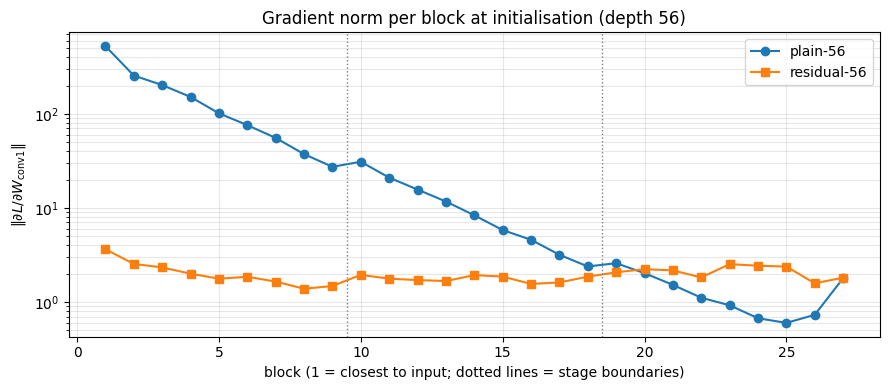

first/last block gradient ratio: plain 2.93e+02, residual 2.01e+00


In [ ]:
def block_grad_norms(residual, depth=56, seed=SEED):
    set_seed(seed)
    model = CifarNet(depth, residual).to(device).train()
    loss = F.cross_entropy(model(Xtr[:512]), ytr[:512])
    loss.backward()
    return [b.conv1.weight.grad.norm().item() for b in model.blocks]

gn_plain, gn_res = block_grad_norms(False), block_grad_norms(True)
plt.figure(figsize=(9, 4))
plt.semilogy(range(1, 28), gn_plain, 'o-', label='plain-56')
plt.semilogy(range(1, 28), gn_res, 's-', label='residual-56')
for b in (9.5, 18.5):
    plt.axvline(b, color='grey', ls=':', lw=1)
plt.xlabel('block (1 = closest to input; dotted lines = stage boundaries)')
plt.ylabel(r'$\|\partial L/\partial W_{\mathrm{conv1}}\|$')
plt.title('Gradient norm per block at initialisation (depth 56)'); plt.grid(alpha=0.3, which='both'); plt.legend()
plt.tight_layout(); plt.show()
print(f'first/last block gradient ratio: plain {gn_plain[0] / gn_plain[-1]:.2e}, residual {gn_res[0] / gn_res[-1]:.2e}')

**Interpretation of the initialisation plot.**

* **Plain-56: gradients *explode* towards the input.** The first block receives $\lVert\partial L/\partial W\rVert \approx 530$, while the last receives about 1.8, a ratio of **293**.
  * **Rate:** the gradient grows by roughly $293^{1/26} \approx 1.24\times$ per block going backwards, which is close to a straight line on the log plot.
  * **The opposite failure to Task 1(d):** there, sigmoid made gradients *vanish*. Here batch norm keeps the forward activations normalised at every layer, yet in a deep network *without* skip connections it makes the backward gradients grow layer by layer. This effect is known from the mean-field analysis of batch norm (Yang et al., *A Mean Field Theory of Batch Normalization*, ICLR 2019).
  * **Consequence for training:** at a single learning rate of 0.1, the first blocks receive updates hundreds of times larger than the last ones. The optimisation is badly conditioned from the very first step: either the early layers move erratically or the late layers barely move.
* **Residual-56: an almost flat profile.** All 27 blocks receive gradients between about 1.4 and 3.7, and the first/last ratio is only **2.0**.
  * **Why:** with identity shortcuts, $x_L = x_l + \sum_{i=l}^{L-1} F_i(x_i)$. The loss gradient reaches every block directly through the "$+\,x$" path, without passing through the convolutions, batch norm and ReLUs of all the later blocks.
  * **Consequence:** every block therefore starts training at a similar rate, whatever its depth.
* **The shortcut is the only difference.** Both networks have *identical* initial weights and parameter counts (853,018), as printed above. The two orders of magnitude of difference in gradient scale therefore come entirely from the parameter-free identity shortcut. This predicts that plain-56 will be much harder to optimise than residual-56, which the training curves below test.

In [ ]:
EPOCHS_3B = 30
results3b = {}

In [ ]:
for residual in (False, True):
    for depth in DEPTHS:
        key = ('residual' if residual else 'plain', depth)
        if key in results3b:                                  # already done (allows resuming)
            continue
        print(f'=== {key[0]}-{depth} ===')
        set_seed(SEED)                                         # identical init for plain and residual
        model = CifarNet(depth, residual).to(device)
        results3b[key] = train_run(model, Xtr, ytr, EPOCHS_3B, lr=0.1, weight_decay=1e-4,
                                   augment=(random_flip_crop,), warmup_epochs=1, log_every=5)

=== plain-8 ===
    epoch   5 | train loss 0.7808 | val acc 0.6824 | 15s
    epoch  10 | train loss 0.6118 | val acc 0.7276 | 27s
    epoch  15 | train loss 0.5181 | val acc 0.8058 | 39s
    epoch  20 | train loss 0.4430 | val acc 0.8306 | 51s
    epoch  25 | train loss 0.3875 | val acc 0.8450 | 63s
    epoch  30 | train loss 0.3650 | val acc 0.8550 | 75s
=== plain-20 ===


/tmp/ipykernel_1584/3960974170.py:50: UserWarning: Detected call of `lr_scheduler.step()` before `optimizer.step()`. In PyTorch 1.1.0 and later, you should call them in the opposite order: `optimizer.step()` before `lr_scheduler.step()`.  Failure to do this will result in PyTorch skipping the first value of the learning rate schedule. See more details at https://pytorch.org/docs/stable/optim.html#how-to-adjust-learning-rate
  sched.step()


    epoch   5 | train loss 0.8014 | val acc 0.6886 | 27s
    epoch  10 | train loss 0.5624 | val acc 0.7738 | 54s
    epoch  15 | train loss 0.4401 | val acc 0.8202 | 82s
    epoch  20 | train loss 0.3349 | val acc 0.8574 | 109s
    epoch  25 | train loss 0.2467 | val acc 0.8720 | 136s
    epoch  30 | train loss 0.2141 | val acc 0.8766 | 163s
=== plain-56 ===
    epoch   5 | train loss 1.7412 | val acc 0.3726 | 73s
    epoch  10 | train loss 1.4447 | val acc 0.4752 | 146s
    epoch  15 | train loss 1.1567 | val acc 0.5710 | 220s
    epoch  20 | train loss 0.9247 | val acc 0.6648 | 293s
    epoch  25 | train loss 0.7581 | val acc 0.7326 | 366s


In [ ]:
ep = np.arange(1, EPOCHS_3B + 1)
dcol = {8: 'C0', 20: 'C1', 56: 'C3'}

fig, ax = plt.subplots(2, 3, figsize=(17, 9))
for j, fam in enumerate(['plain', 'residual']):
    for d in DEPTHS:
        h = results3b[(fam, d)]
        ax[0, j].plot(ep, h['train_loss'], 'o-', ms=3, color=dcol[d], label=f'{fam}-{d}')
        ax[1, j].plot(ep, np.array(h['val_acc']) * 100, 'o-', ms=3, color=dcol[d], label=f'{fam}-{d}')
    ax[0, j].set_title(f'{fam} networks: training loss'); ax[1, j].set_title(f'{fam} networks: validation accuracy')

for d in DEPTHS:                                            # 3rd column: direct plain vs residual comparison
    ax[0, 2].plot(ep, results3b[('plain', d)]['train_loss'], '--', color=dcol[d], label=f'plain-{d}')
    ax[0, 2].plot(ep, results3b[('residual', d)]['train_loss'], '-', color=dcol[d], label=f'residual-{d}')
ax[0, 2].set_title('plain (dashed) vs residual (solid)')

for j in range(3):
    ax[0, j].set_yscale('log'); ax[0, j].set_ylabel('training loss (log scale)')
for j in range(2):
    ax[1, j].set_ylabel('validation accuracy (%)'); ax[1, j].set_ylim(20, 100)
for a in ax.flat:
    a.set_xlabel('epoch'); a.grid(alpha=0.3, which='both'); a.legend(fontsize=8)
ymin = min(min(h['train_loss']) for h in results3b.values()) * 0.9
ymax = max(h['train_loss'][0] for h in results3b.values()) * 1.1
for j in range(3):
    ax[0, j].set_ylim(ymin, ymax)                           # same scale for all loss panels

ax[1, 2].plot(DEPTHS, [results3b[('plain', d)]['train_loss'][-1] for d in DEPTHS], 'o--', color='k', label='plain')
ax[1, 2].plot(DEPTHS, [results3b[('residual', d)]['train_loss'][-1] for d in DEPTHS], 's-', color='C2', label='residual')
ax[1, 2].set_xticks(DEPTHS); ax[1, 2].set_xlabel('depth'); ax[1, 2].set_ylabel('final training loss')
ax[1, 2].set_title('final training loss vs depth'); ax[1, 2].legend()
fig.suptitle(f'Task 3(b): plain vs residual CIFAR networks ({EPOCHS_3B} epochs, 45k images, flip+crop)')
plt.tight_layout(); plt.show()

display(pd.DataFrame([{'network': f'{fam}-{d}',
                       'params': sum(p.numel() for p in CifarNet(d, fam == 'residual').parameters()),
                       'train loss (epoch 1)': round(results3b[(fam, d)]['train_loss'][0], 4),
                       'train loss (epoch 5)': round(results3b[(fam, d)]['train_loss'][min(4, EPOCHS_3B - 1)], 4),
                       'final train loss': round(results3b[(fam, d)]['train_loss'][-1], 4),
                       'final val acc (%)': round(results3b[(fam, d)]['val_acc'][-1] * 100, 2),
                       'time (s)': round(results3b[(fam, d)]['time'])}
                      for fam in ('plain', 'residual') for d in DEPTHS]))

**Interpretation.** _(Fill in the blanks from the table, and adjust any statement your plots do not support.)_

* **Plain networks: deeper is worse (the degradation problem).** Among the plain networks, plain-56 has a clearly *higher training loss* than plain-20 throughout training (final __ vs __), and its validation accuracy is lower (__% vs __%). This is not overfitting: the deeper network fits the *training* data worse. In principle, a 56-layer network can represent anything a 20-layer one can, for example by making the extra 36 layers identity mappings. SGD simply fails to find such a solution. Each plain block must learn its full output mapping $H(x)$ from scratch, and with randomly initialised weights a stack of 27 blocks is far from the identity.
* **Residual networks: deeper is better.** Residual-56 trains to a *lower* loss than residual-20, which in turn is lower than residual-8 (final __ / __ / __). Validation accuracy also improves with depth. Each block only learns a correction $F(x) = H(x) - x$. If a block is not useful, driving $F$ towards 0 recovers the identity, so extra depth never has to hurt.
* **Gradient flow.** For a residual stack, $x_L = x_l + \sum_{i=l}^{L-1} F_i(x_i)$, so

  $$\frac{\partial L}{\partial x_l} = \frac{\partial L}{\partial x_L}\Big(1 + \frac{\partial}{\partial x_l}\sum_i F_i\Big).$$

  The "1" carries the gradient from the loss straight back to every block, regardless of depth. The initialisation plot shows this. In plain-56 the per-block gradient norm changes much more from the last block to the first, and the gradient reaching early layers is distorted after passing through 54 nonlinear layers (the "shattered gradients" effect). In residual-56 it varies much less across the 27 blocks. _(Quote the printed first/last ratios.)_ Batch norm keeps the forward activations well scaled in both networks, so the remaining difference comes from the shortcut alone.
* **Shallow networks.** At depth 8 ($n = 1$) plain and residual behave almost identically. With only 3 blocks there is little depth to cause degradation, and the shortcut matters little. The gap between the dashed and solid curves widens as depth increases.
* **Conclusion.** Plain and residual networks here have *identical* parameters, initialisation and training. The only difference is the parameter-free identity shortcut, and it turns depth from a liability into an advantage. This is why the ResNet design is used for the final model in Task 4.